# D8 · Temperatura del agua almacenada y horas de residencia

**Integrante responsable: Josué Gabriel Ochoa Mamani**

Notebook de sustentación de la dimensión D8 (Unidad 2, Grupo Horeb, MonitorAqua).

- **Modelo versionado:** `d8.1` (`batch/modelos/d8/d8.1-20261029/modelo.json`): inercia térmica de primer orden
  (aire de la cámara + Open-Meteo), con banda conforme, probabilidad de cruce de umbral y residencia del agua.
- **Sin modelo propio:** todo se importa de `batch/modelo_d8.py`, `batch/termico.py` y `batch/evaluacion.py`.
- **Fuente de verdad:** `docs/modelo-d8.md` y `docs/evidencias/f6-d8/`.
- **Advertencia:** el único dato real de temperatura del agua es el canal ThingSpeak 3418755 (DS18B20); en Juliaca
  (ESP32 y flota) el resultado es una **transferencia**, no una medición.

In [1]:
# Dependencias que la imagen de Jupyter no trae (lectura de Parquet y gráficos). Versiones fijas.
%pip install -q --root-user-action=ignore --disable-pip-version-check pyarrow==19.0.1 matplotlib==3.10.7

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/u2/soporte_u2.py
import soporte_u2 as su                        # agrega batch/, ingesta/ y streaming/ al path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import evaluacion as ev
import modelo_d8 as m
from termico import ModeloTermico
RAIZ = su.RAIZ
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)
MODELO = RAIZ / "batch/modelos/d8/d8.1-20261029"
PUB = json.loads((RAIZ / "docs/evidencias/f6-d8/resultados_d8.json").read_text(encoding="utf-8"))
print("Repositorio:", RAIZ)

Repositorio: /work/MonitorAqua


## 1. Pregunta y datos

**Pregunta:** ¿a qué temperatura está el agua ahora y a cuánto en 6 y 12 h? ¿Puede cruzar un umbral de riesgo
(helada o agua tibia) en 12 h? ¿Cuántas horas lleva almacenada?

**Datos:** tabla oro `d8_termica` (1 h) y la rejilla horaria del canal 3418755: aire dentro del tanque, agua real
(DS18B20) y Open-Meteo de su ubicación (53.45, −2.51). Partición **p6.2**: entrenamiento, ajuste (último 20 % del
entrenamiento), embargo y prueba (últimos 8 días).

In [3]:
oro = ev.leer_oro("d8_termica")
print("Partición de la tabla oro:", ", ".join(oro["particion_version"].unique()))
display(pd.crosstab(oro["fuente"].map(ev.nivel_de), oro["particion"], margins=True, margins_name="total").rename_axis(index="nivel"))
g = m.grilla_canal()
U = {"aire": g["aire"].to_numpy(), "om": g["om"].to_numpy()}
hora, agua = g["hora"].to_numpy(), g["agua"].to_numpy()
print("Canal 3418755 · horas con agua medida por conjunto:",
      {k: int(((g["conj"] == k) & g["agua"].notna()).sum()) for k in ("entrenamiento", "ajuste", "embargo", "prueba")})

Partición de la tabla oro: p6.2


particion,consistencia,embargo,entrenamiento,prueba,total
nivel,,,,,
consistencia,1536,192,4032,0,5760
esp32_real,0,0,34,0,34
thingspeak_real,0,24,1414,296,1734
total,1536,216,5480,296,7528


Canal 3418755 · horas con agua medida por conjunto: {'entrenamiento': 1131, 'ajuste': 283, 'embargo': 24, 'prueba': 168}


## 2. Líneas base

| Línea base | Agua estimada |
|---|---|
| **(a) aire actual** | agua = aire de este momento |
| **(b) media del aire 24 h** | agua = media móvil del aire de las últimas 24 h |
| **(c) regla provisional f4.4** | inercia con τ = 25.2 h, ganancia 1, solo aire (la de `umbral_termico`, congelada) |

In [4]:
bases, _ = m.predicciones_bases(g)
print("Líneas base calculadas:", list(bases))

Líneas base calculadas: ['base_a_aire_actual', 'base_b_media_aire_24h', 'base_c_provisional_f44']


## 3. Modelo: carga del versionado y reentrenamiento verificado

Se reentrenan las tres variantes con `ModeloTermico.ajustar` sobre el entrenamiento y se comparan τ, ganancias,
constante y banda con `batch/modelos/d8/d8.1-20261029/modelo.json`. La principal se elige en el ajuste, antes de mirar
la prueba.

In [5]:
guardado = json.loads((MODELO / "modelo.json").read_text(encoding="utf-8"))
mascara = (g["conj"] == "entrenamiento").to_numpy()
t0 = time.time()
modelos = {n: ModeloTermico.ajustar(U, agua, mascara, e, m.taus(), nombre=n) for n, e in m.CFG["modelos"].items()}
preds = {n: m.predicciones_modelo(mod, U, hora) for n, mod in modelos.items()}
todas = {**preds, **bases}
diseno = m.evaluar_temperatura(g, todas, "ajuste")
principal = min(modelos, key=lambda n: diseno["0h"][n]["MAE"]["valor"])
for n, mod in modelos.items():
    mod.calibrar(m.residuos(g, preds[n], "ajuste"), m.CFG["conforme"]["alfa"], m.CFG["conforme"]["min_n"])
print(f"Reentrenado en {time.time() - t0:.0f} s · principal elegida en el ajuste: {principal} (guardada: {guardado['principal']})")
filas = []
for n, mod in modelos.items():
    i, t, d = su.comparar(mod.a_dict(), guardado["modelos"][n])
    a = mod.a_dict()
    filas.append({"variante": n, "parámetros idénticos": f"{i}/{t}", "τ (h)": round(mod.tau, 2),
                  "ganancias": dict(zip(mod.entradas, np.round(mod.ganancias, 3))), "constante (°C)": round(mod.constante, 3)})
tabla_par = pd.DataFrame(filas)
display(tabla_par)
assert principal == guardado["principal"]
assert all(x.split("/")[0] == x.split("/")[1] for x in tabla_par["parámetros idénticos"]), "parámetros distintos"
print("Verificado: las tres variantes reentrenadas son idénticas a las guardadas")

Reentrenado en 2 s · principal elegida en el ajuste: aire_y_om (guardada: aire_y_om)


,variante,parámetros idénticos,τ (h),ganancias,constante (°C)
0,aire_y_om,56/56,24.32,"{'aire': 0.451, 'om': 0.584}",-0.492
1,solo_aire,55/55,27.94,{'aire': 0.989},-0.447
2,solo_om,55/55,22.69,{'om': 0.899},2.046


Verificado: las tres variantes reentrenadas son idénticas a las guardadas


## 4. Resultados por nivel

Evaluación con las funciones de `batch/modelo_d8.py` (temperatura, cobertura, cruce de umbral, precisión del DHT11,
transferencia a Juliaca y residencia), comparación número a número con `docs/evidencias/f6-d8/resultados_d8.json` y
regeneración de `tablas_d8.md` (la de `docs/modelo-d8.md`).

In [6]:
t0 = time.time()
prueba = m.evaluar_temperatura(g, todas, "prueba")
cob = {n: {"ajuste": m.cobertura(g, mod, preds[n], "ajuste"), "prueba": m.cobertura(g, mod, preds[n], "prueba")}
       for n, mod in modelos.items()}
res_aj = m.residuos(g, preds[principal], "ajuste")
cruce = m.evaluar_cruce(g, preds[principal], bases, res_aj)
dht = m.precision_dht(g, modelos)
boot = m.ajustes_bootstrap(g, modelos[principal].entradas)
transf = m.transferencia(principal, modelos, boot)
temp_flota = []
for (run, sid), t in oro[oro["fuente"].str.startswith("aumentado")].groupby(["runId", "sensorId"]):
    t = t.sort_values("ts")
    w = modelos[principal].estimar({"aire": t["temp_aire_camara_c"].to_numpy(), "om": t["temp_juliaca_c"].to_numpy()})
    temp_flota.append(pd.DataFrame({"runId": run, "sensorId": sid, "hora": t["ts"].to_numpy(), "agua_estimada": w}))
edades, resumen_res = m.residencia()
rel = m.relacion_residencia_temperatura(edades, g, pd.concat(temp_flota))
print(f"Evaluación en {time.time() - t0:.0f} s")
c = g["conj"]
res = {"version": m.CFG["version"], "principal": principal, "parametros": {n: mod.a_dict() for n, mod in modelos.items()},
       "datos_canal": {"horas": int(g["agua"].notna().sum()), "relleno_aire": g.attrs["relleno"],
                       "horas_por_conjunto": {k: int(((c == k) & g["agua"].notna()).sum()) for k in ("entrenamiento", "ajuste", "embargo", "prueba")}},
       "temperatura": {"diseno_ajuste": diseno, "prueba": prueba}, "cobertura_banda": cob, "cruce": cruce,
       "precision_dht11": dht, "transferencia_juliaca": transf,
       "tau_bootstrap": {"p10": float(np.percentile([b.tau for b in boot], 10)), "p50": float(np.median([b.tau for b in boot])),
                         "p90": float(np.percentile([b.tau for b in boot], 90))},
       "residencia": {"por_tanque": resumen_res, "relacion_temperatura": rel}}
for parte in res:
    if parte in PUB:
        su.informe_comparacion(parte, {parte: res[parte]}, {parte: PUB[parte]})
publicado = {**PUB, **su.normalizar(res)}
su.misma_tabla(m.tablas_md(publicado), RAIZ / "docs/evidencias/f6-d8/tablas_d8.md")

/work/MonitorAqua/batch/modelo_d8.py:236: RuntimeWarning: All-NaN slice encountered
  binario = (np.nanmin(fut, 1) < u) if lado == "bajo" else (np.nanmax(fut, 1) > u)


Evaluación en 13 s
version: 0 de 0 números idénticos a lo publicado
principal: 0 de 0 números idénticos a lo publicado
parametros: 166 de 166 números idénticos a lo publicado
datos_canal: 8 de 8 números idénticos a lo publicado
temperatura: 618 de 618 números idénticos a lo publicado
cobertura_banda: 54 de 54 números idénticos a lo publicado
cruce: 229 de 229 números idénticos a lo publicado
precision_dht11: 14 de 14 números idénticos a lo publicado
transferencia_juliaca: 69 de 69 números idénticos a lo publicado
tau_bootstrap: 3 de 3 números idénticos a lo publicado
residencia: 52 de 52 números idénticos a lo publicado
tablas_d8.md: idéntica a la regenerada con los datos de hoy


True

In [7]:
filas = []
for conj, bloque in (("prueba (8 días)", prueba), ("ajuste (13 días)", diseno)):
    for h in ("0h", "6h", "12h"):
        for pred, mt in bloque[h].items():
            if pred.startswith("_"):
                continue
            y, pr, _ = m.pares(g, todas[pred], int(h[:-1]), "prueba" if conj.startswith("prueba") else "ajuste")
            filas.append({"conjunto": conj, "horizonte": h, "predictor": pred + (" (principal)" if pred == principal else ""),
                          "n": mt["n"], "MAE °C": su.fm(mt["MAE"]), "RMSE °C": su.fm(mt["RMSE"]),
                          "sesgo °C": round(mt["SESGO"]["valor"], 2), "R²": round(su.r2(y, pr), 3)})
tabla = pd.DataFrame(filas)
display(Markdown("**Temperatura del agua en el canal real 3418755 (DS18B20)**"))
display(tabla[tabla["conjunto"].str.startswith("prueba")])
display(Markdown("**ESP32 y flota de Juliaca: transferencia, no medición** (no hay sensor de agua; la métrica real del "
                 "ESP32 queda pendiente). Agua estimada por el modelo principal y diferencia con la regla provisional:"))
display(pd.DataFrame([{"fuente": f, "tanques": t["tanques"], "horas": t["horas"],
                       "principal P05 / P50 / P95 (°C)": "{p05:.1f} / {p50:.1f} / {p95:.1f}".format(**t["estimacion_c"][principal]),
                       "provisional f4.4 P50": round(t["estimacion_c"]["provisional_f44"]["p50"], 1),
                       "|principal − provisional| (°C)": round(t["dif_principal_vs_provisional_c"]["media_abs"], 2),
                       "incertidumbre de parámetros P10-P90 (°C)": round(t["incertidumbre_parametros_p10_p90_c"]["ancho_mediano"], 2),
                       "horas < 4 °C": t["estimacion_c"][principal]["horas_bajo_4c"]} for f, t in transf.items()]))

**Temperatura del agua en el canal real 3418755 (DS18B20)**

,conjunto,horizonte,predictor,n,MAE °C,RMSE °C,sesgo °C,R²
0,prueba (8 días),0h,aire_y_om (principal),168,"0.16 [0.10, 0.23]","0.21 [0.14, 0.27]",0.13,0.960
1,prueba (8 días),0h,solo_aire,168,"0.91 [0.57, 1.36]","1.10 [0.80, 1.45]",-0.87,-0.109
2,prueba (8 días),0h,solo_om,168,"1.79 [1.70, 2.03]","1.82 [1.71, 2.06]",1.79,-2.050
3,prueba (8 días),0h,base_a_aire_actual,168,"0.22 [0.18, 0.26]","0.23 [0.20, 0.27]",-0.21,0.951
4,prueba (8 días),0h,base_b_media_aire_24h,168,"0.41 [0.28, 0.63]","0.53 [0.36, 0.74]",-0.33,0.741
5,prueba (8 días),0h,base_c_provisional_f44,168,"0.61 [0.46, 0.82]","0.70 [0.52, 0.92]",-0.33,0.543
6,prueba (8 días),6h,aire_y_om (principal),168,"0.24 [0.17, 0.33]","0.31 [0.23, 0.40]",0.12,0.914
7,prueba (8 días),6h,solo_aire,168,"0.91 [0.57, 1.36]","1.10 [0.78, 1.46]",-0.84,-0.113
8,prueba (8 días),6h,solo_om,168,"1.75 [1.64, 2.04]","1.81 [1.68, 2.10]",1.75,-2.024
9,prueba (8 días),6h,base_a_aire_actual,168,"0.35 [0.26, 0.48]","0.44 [0.33, 0.57]",-0.28,0.825


**ESP32 y flota de Juliaca: transferencia, no medición** (no hay sensor de agua; la métrica real del ESP32 queda pendiente). Agua estimada por el modelo principal y diferencia con la regla provisional:

,fuente,tanques,horas,principal P05 / P50 / P95 (°C),provisional f4.4 P50,|principal − provisional| (°C),incertidumbre de parámetros P10-P90 (°C),horas < 4 °C
0,aumentado_f2b1,4,2592,8.7 / 10.3 / 11.7,10.5,0.86,0.50,0
1,aumentado_f2b2,4,2592,8.0 / 9.9 / 11.6,9.7,0.72,0.55,0
2,esp32,1,34,9.8 / 10.4 / 12.6,12.7,1.89,0.63,0


**Lectura (igual que `docs/modelo-d8.md`):** la variante principal (aire + Open-Meteo) gana a todas las líneas base
en ajuste y en prueba: 0.16 °C ahora, 0.24 °C a 6 h y 0.41 °C a 12 h. Una sola entrada no alcanza (sesgo −0.9 °C solo
aire, +1.8 °C solo Open-Meteo). En Juliaca, el error de transferencia es de 1-2 °C porque τ depende del recipiente.

## 5. Gráficos

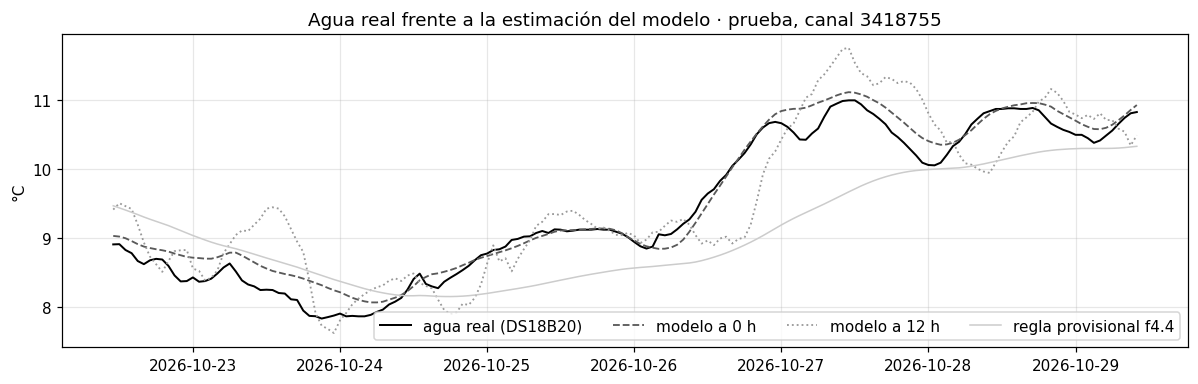

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for h, estilo in ((0, "--"), (12, ":")):
    y, pr, ts = m.pares(g, preds[principal], h, "prueba")
    t = pd.to_datetime(ts, unit="ms", utc=True).tz_convert("America/Lima")
    if h == 0:
        ax.plot(t, y, "k-", lw=1.3, label="agua real (DS18B20)")
    ax.plot(t, pr, estilo, color="0.35" if h == 0 else "0.6", lw=1.2, label=f"modelo a {h} h")
ya, pa, ta = m.pares(g, bases["base_c_provisional_f44"], 0, "prueba")
ax.plot(pd.to_datetime(ta, unit="ms", utc=True).tz_convert("America/Lima"), pa, "-", color="0.8", lw=1, label="regla provisional f4.4")
ax.set(title="Agua real frente a la estimación del modelo · prueba, canal 3418755", ylabel="°C"); ax.legend(ncol=4)
plt.tight_layout(); plt.show()

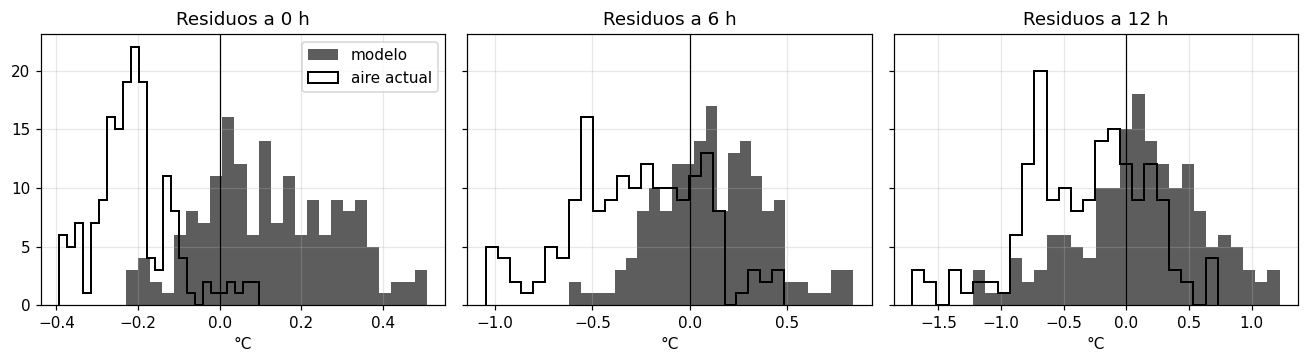

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, h in zip(axs, (0, 6, 12)):
    y, pr, _ = m.pares(g, preds[principal], h, "prueba")
    yb, pb, _ = m.pares(g, bases["base_a_aire_actual"], h, "prueba")
    ax.hist(pr - y, bins=25, color="0.25", alpha=0.85, label="modelo")
    ax.hist(pb - yb, bins=25, histtype="step", color="k", lw=1.3, label="aire actual")
    ax.axvline(0, color="k", lw=0.8); ax.set(title=f"Residuos a {h} h", xlabel="°C")
axs[0].legend(); plt.tight_layout(); plt.show()

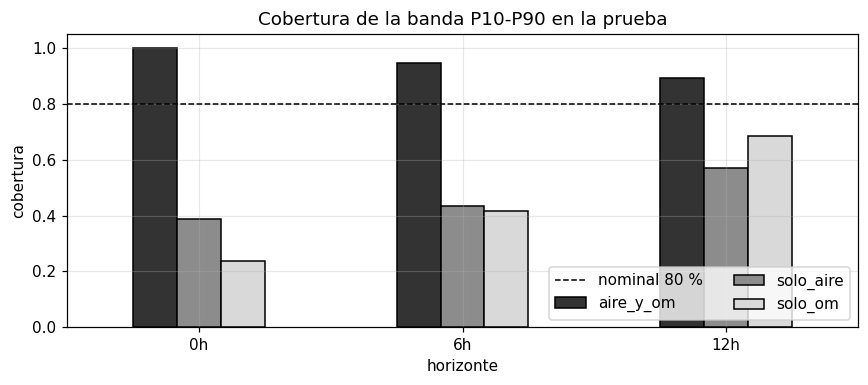

,aire_y_om,solo_aire,solo_om
horizonte,,,
0h,1.000,0.387,0.238
6h,0.946,0.435,0.417
12h,0.893,0.571,0.685


In [10]:
filas = [{"horizonte": h, **{n: cob[n]["prueba"][h].get("cobertura", np.nan) for n in modelos}} for h in ("0h", "6h", "12h")]
cb = pd.DataFrame(filas).set_index("horizonte")
ax = cb.plot.bar(color=["0.2", "0.55", "0.85"], edgecolor="k", figsize=(8, 3.6), rot=0)
ax.axhline(0.8, color="k", ls="--", lw=1, label="nominal 80 %"); ax.set_ylim(0, 1.05)
ax.set(title="Cobertura de la banda P10-P90 en la prueba", ylabel="cobertura"); ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.show()
display(cb.round(3))

## 6. En vivo (F7): últimas predicciones y pronóstico frente a real

La consulta `predicciones` del job de Spark (F7) aplica este mismo modelo versionado a cada micro-lote y escribe en
InfluxDB (measurement `predicciones`, `dimension = D8`). Se leen las últimas estimaciones y las verificaciones
(`tipo = verificacion`: el pronóstico comparado con lo que pasó de verdad en el instante objetivo). Los datos reales
están en el bucket `monitoraqua`; la flota extrapolada, en `monitoraqua_aumentados` (fechas simuladas 28-sep a 28-oct).

In [11]:
est = su.predicciones("D8", "estimacion", horas=48, limite=400)
if len(est):
    ult = est.sort_values("_time").groupby("sensorId").tail(1)
    cols = [c for c in ["_time", "sensorId", "version_modelo", *['variante', 'agua_c', 'agua_p10_c', 'agua_p90_c', 'agua_6h_c', 'agua_12h_c', 'prob_cruce_bajo_12h', 'prob_cruce_alto_12h', 'residencia_h'], "advertencia"] if c in ult]
    display(ult[cols].reset_index(drop=True))
else:
    print("Sin estimaciones reales en las últimas 48 h")
mot = su.predicciones("D8", "motivo", horas=48, limite=400)
if len(mot):
    mot = mot.sort_values("_time").groupby("sensorId").tail(1)
    if len(est):   # vigente: solo si el tanque no tuvo una estimación posterior al motivo
        ult_est = est.groupby("sensorId")["_time"].max()
        mot = mot[mot["_time"] > mot["sensorId"].map(ult_est).fillna(pd.Timestamp(0, tz="America/Lima"))]
    print("Tanques reales donde hoy el modelo no aplica (motivo vigente):")
    display(mot[["_time", "sensorId", "motivo"]].reset_index(drop=True))

,_time,sensorId,version_modelo,variante,agua_c,agua_p10_c,agua_p90_c,agua_6h_c,agua_12h_c,prob_cruce_bajo_12h,prob_cruce_alto_12h,residencia_h,advertencia
0,2026-10-30 01:00:00-05:00,thingspeak-480876,d8.1-20261029,solo_aire,25.04,24.38,25.84,25.11,25.17,0,0.6713,NaN,estimación sin sensor de agua; error de transf...
1,2026-10-30 01:00:00-05:00,thingspeak-3418755,d8.1-20261029,aire_y_om,8.92,8.35,9.27,8.86,8.82,0,0.0000,NaN,estimación sin sensor de agua; error de transf...
2,2026-10-30 01:00:00-05:00,esp32-tanque-real-01,d8.1-20261029,aire_y_om,9.66,9.09,10.00,9.27,8.98,0,0.0000,10.58,estimación sin sensor de agua; error de transf...


Tanques reales donde hoy el modelo no aplica (motivo vigente):


,_time,sensorId,motivo
0,2026-10-30 01:00:00-05:00,thingspeak-3019316,sin temperatura del aire en este canal
1,2026-10-30 01:00:00-05:00,thingspeak-283977,sin temperatura del aire en este canal
2,2026-10-30 01:00:00-05:00,thingspeak-1272968,sin temperatura del aire en este canal
3,2026-10-30 01:00:00-05:00,thingspeak-1233815,sin temperatura del aire en este canal
4,2026-10-30 01:00:00-05:00,thingspeak-1233810,sin temperatura del aire en este canal


In [12]:
ver_real = su.predicciones("D8", "verificacion", horas=48)
ver_flota = su.predicciones("D8", "verificacion", bucket="monitoraqua_aumentados", horas=1440)
for nombre, v in (("real", ver_real), ("flota", ver_flota)):
    if len(v) and "agua_real_c" in v and "agua_pred_c" in v:
        v = v.dropna(subset=["agua_real_c", "agua_pred_c"])
        err = (v["agua_real_c"] - v["agua_pred_c"]) * 1.0
        r2 = "" if 1.0 != 1.0 else f" · R² {su.r2(v['agua_real_c'], v['agua_pred_c']):.3f}"
        print(f"{nombre}: {len(v)} pronósticos verificados · MAE en vivo {err.abs().mean():.3f} · "
              f"sesgo {(-err).mean():+.3f}{r2}")
        display(v.assign(_e=err.abs()).groupby("sensorId")["_e"].agg(verificados="count", MAE="mean").round(3))
    else:
        print(f"{nombre}: todavía sin verificaciones de D8 (ver docs/inferencia-en-vivo.md, pendientes)")

real: todavía sin verificaciones de D8 (ver docs/inferencia-en-vivo.md, pendientes)
flota: todavía sin verificaciones de D8 (ver docs/inferencia-en-vivo.md, pendientes)


In [13]:
v = ver_flota if len(ver_flota) else ver_real
if len(v) and "agua_real_c" in v:
    v = v.dropna(subset=["agua_real_c", "agua_pred_c"])
    s = v["sensorId"].value_counts().index[0]
    g = v[v["sensorId"] == s].sort_values("_time")
    fig, ax = plt.subplots(figsize=(11, 3.2))
    if 1.0 != 1.0:   # D4: error de la hora de llegada en horas
        ax.bar(g["_time"], (g["agua_real_c"] - g["agua_pred_c"]) * 1.0, width=0.05, color="0.3")
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("real − pronosticada (h)")
    else:
        ax.plot(g["_time"], g["agua_real_c"], "k-", lw=1.2, label="real")
        ax.plot(g["_time"], g["agua_pred_c"], "--", color="0.45", lw=1.2, label="pronosticado (F7)"); ax.legend()
    ax.set_title(f"D8 · agua real vs pronosticada · {s}"); plt.tight_layout(); plt.show()

## 7. Limitaciones (copiadas de `docs/modelo-d8.md`)

In [14]:
display(Markdown(su.secciones("modelo-d8.md", ['Limitaciones'])))

## 9. Limitaciones

- **Un solo canal real, en otro clima, con 8 días de prueba:** el tanque de 3418755 es de lluvia, en Inglaterra,
  con otro tamaño y aislamiento. El método se valida con datos reales; los parámetros, en Juliaca, son un supuesto.
- **τ depende del recipiente:** el del ESP32 es mucho más pequeño y su τ real sería de ~4-10 h, no 24 h. Es la
  causa principal del error de transferencia (1-2 °C de media) y solo se corrige midiendo el agua (DS18B20, opcional).
- **Septiembre-octubre:** no hay invierno ni verano en los datos. Los umbrales de riesgo (4 y 25 °C) no ocurrieron, así
  que la probabilidad de cruce se calibró con umbrales de evaluación.
- **El volumen del tanque no entra en τ.** Un tanque casi vacío cambia de temperatura más rápido que uno lleno.
  Agregar el nivel como modulador de τ queda para d8.2.
- **Sin el DHT11, solo Open-Meteo:** es la variante con más sesgo en la prueba (+1.8 °C). En Juliaca el ESP32 casi no
  transmite de noche, justo cuando importa la helada.
- **Residencia:** depende de detectar bien los llenados (D4) y de que el tanque esté bien mezclado; con estratificación
  (agua nueva arriba, vieja abajo) la edad real del fondo es mayor.
